# PCA frente a PINN base al inicio del entrenamiento

Análisis retrospectivo de validación guardada, sin nuevos entrenamientos ni uso de prueba. La comparación principal usa PCA al 99% en diez casos: Burgers, tres condiciones de advección, tres dimensiones alineadas, un control desalineado y dos condiciones de onda. Se conserva una sola trayectoria por modelo/caso/semilla: se evita contar repetidamente prefijos de 2000 y 5000 pasos o controles reproducidos. Estos casos comparten familias, semillas e hipótesis: no son diez réplicas independientes.

## Qué significan los primeros pasos

Los primeros checkpoints comunes disponibles son 100, 200 y 500. No hay información común para afirmar qué ocurre en los pasos 1–99 ni antes de entrenar. Se evalúa error de u con RMSE de validación; no se guardó residuo PDE de validación en todos esos pasos y no se infiere de la pérdida de entrenamiento.

La razón es media RMSE PCA / media RMSE base dentro del mismo caso. Menor que 1 favorece PCA. La banda ±5% es descriptiva y se fijó en la configuración de este análisis; no es un umbral de significación. Las semillas están pareadas y los conteos indican cuántas obtienen menor RMSE con PCA. Los k fijos, pesos físicos y escalas alternativas se muestran aparte y no se elige el mejor retrospectivamente.

## Ventana completa y tiempo

El promedio de RMSE en 100–500 se calcula por regla trapezoidal sobre checkpoints observados, dividido por la longitud de la ventana. Es un resumen aproximado entre observaciones, no una medición continua. Evita juzgar todo el inicio a partir del único checkpoint favorable de 100 pasos.

Para tiempo se usa la última evaluación registrada antes de 0.5, 1 y 2 s. No se interpola al tiempo exacto ni se inventan resultados cuando no existe observación. La tabla indica pares faltantes y la figura solo colorea comparaciones con todos los pares. El tiempo incluye ajuste PCA y validaciones; excluye compilación. Las corridas de fechas distintas conservan sus tiempos medidos y solo se comparan modelos dentro de su corrida.

In [ ]:
from pathlib import Path
import json,sys
from IPython.display import display,HTML,SVG
ROOT=Path.cwd()
while not (ROOT/'pyproject.toml').exists() and ROOT!=ROOT.parent:
    ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
from pinn_pca.early_training import primary_table,counts_table,time_table,secondary_table
RUN_DIR=ROOT/'results/early_training'
REPORT=json.loads((RUN_DIR/'summary.json').read_text(encoding='utf-8'))

## Comparación principal: PCA al 99%

Cada celda contiene la razón y el número de semillas con RMSE menor con PCA.

In [ ]:
display(HTML(primary_table(REPORT)))

Caso,Paso 100: razón y semillas PCA menor,Paso 200: razón y semillas PCA menor,Paso 500: razón y semillas PCA menor,Ventana 100–500: razón y semillas PCA menor
Burgers,0.534× (10/10),0.605× (10/10),0.686× (10/10),0.617× (10/10)
Advección: 2 frecuencias,0.797× (7/10),1.562× (1/10),2.476× (0/10),1.652× (1/10)
Advección: 4 armónicos,0.821× (7/10),1.415× (1/10),1.441× (0/10),1.328× (1/10)
Advección: 6 armónicos,0.892× (7/10),1.231× (1/10),1.444× (0/10),1.245× (0/10)
Entradas alineadas: d=5,0.976× (7/10),0.983× (5/10),0.955× (5/10),0.978× (6/10)
Entradas alineadas: d=10,0.967× (6/10),0.983× (8/10),0.928× (7/10),0.959× (7/10)
Entradas alineadas: d=20,0.924× (7/10),0.932× (6/10),0.920× (8/10),0.937× (8/10)
Entradas desalineadas: d=20,0.934× (7/10),0.993× (6/10),0.998× (5/10),0.986× (7/10)
Onda: 2 frecuencias,0.947× (7/10),0.934× (7/10),1.419× (0/10),1.071× (1/10)
Onda: 3 frecuencias,0.947× (7/10),0.933× (7/10),1.373× (0/10),1.057× (2/10)


In [ ]:
display(HTML(counts_table(REPORT)))

Checkpoint/ventana,Casos,PCA menor >5%,Similar ±5%,PCA mayor >5%
100,10,8,2,0
200,10,4,3,3
500,10,3,2,5
window_100_500,10,2,3,5


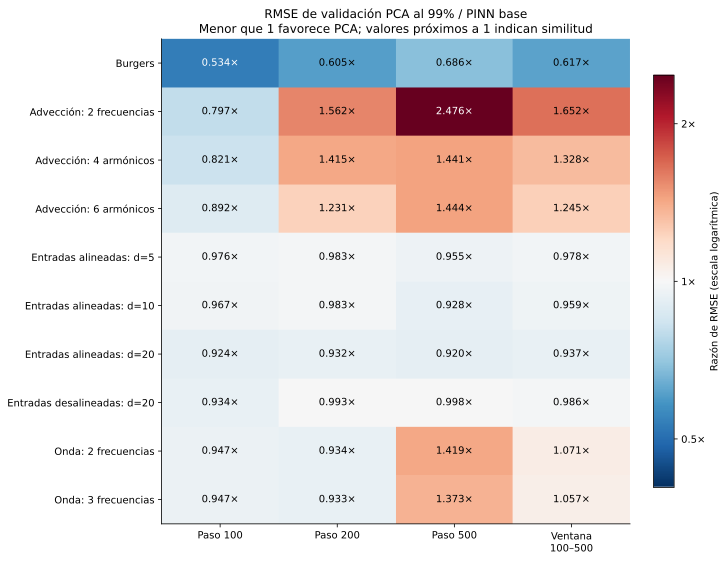

In [ ]:
display(SVG(filename=str(RUN_DIR/'early_rmse_ratios.svg')))

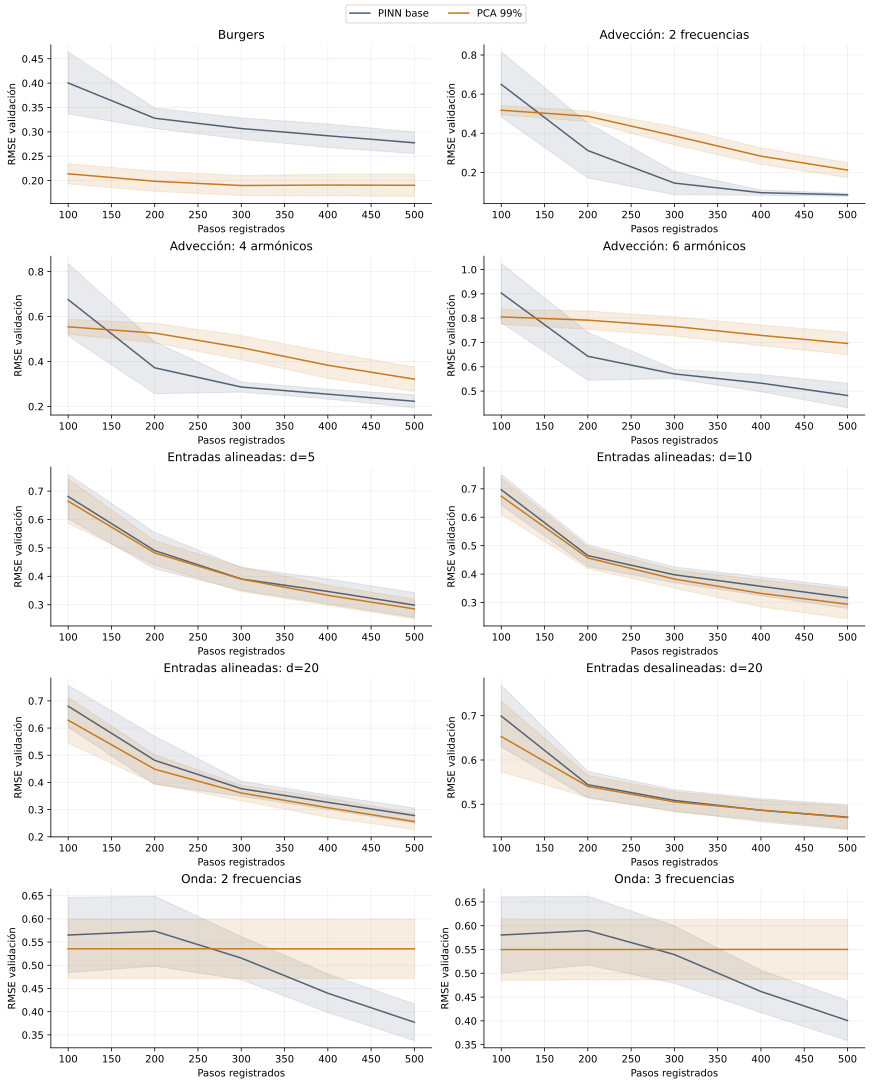

In [ ]:
display(SVG(filename=str(RUN_DIR/'first_500_steps.svg')))

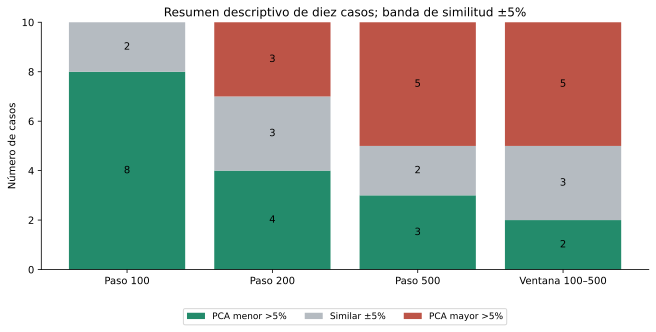

In [ ]:
display(SVG(filename=str(RUN_DIR/'case_counts.svg')))

## Presupuesto de tiempo: aproximación con registros disponibles

Se comparan los últimos estados evaluados antes de cada presupuesto, que pueden corresponder a pasos distintos. No equivale a reevaluar el modelo exactamente a T segundos. Los pares sin evaluación de ambos modelos se excluyen y se cuentan explícitamente. No comparar valores absolutos entre PDE.

In [ ]:
display(HTML(time_table(REPORT)))

Caso,Presupuesto (s),Pares observados,Razón RMSE PCA/base,Semillas PCA menor
Burgers,0.5,10/10,0.541×,10/10
Burgers,1.0,10/10,0.636×,10/10
Burgers,2.0,10/10,0.726×,10/10
Advección: 2 frecuencias,0.5,10/10,2.288×,0/10
Advección: 2 frecuencias,1.0,10/10,1.634×,0/10
Advección: 2 frecuencias,2.0,10/10,1.616×,0/10
Advección: 4 armónicos,0.5,10/10,1.370×,1/10
Advección: 4 armónicos,1.0,10/10,1.204×,3/10
Advección: 4 armónicos,2.0,10/10,1.712×,0/10
Advección: 6 armónicos,0.5,10/10,1.290×,0/10


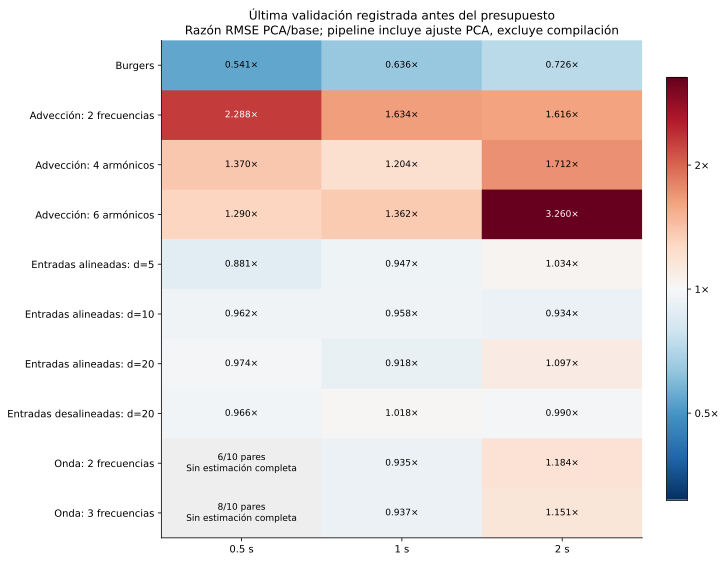

In [ ]:
display(SVG(filename=str(RUN_DIR/'early_time_budgets.svg')))

## Variantes adicionales

Se conservan todos los modelos de cada corrida elegida, incluidos k fijos, pesos de Burgers y estandarización de la onda. No se suman al conteo principal: hacerlo daría más peso a los problemas con más variantes. Las comparaciones con distintos pesos de pérdida no aíslan PCA.

In [ ]:
display(HTML(secondary_table(REPORT)))

Caso,Variante adicional,Paso,Razón RMSE PCA/base,Semillas PCA menor
Burgers,PCA k=4,100,0.487×,10/10
Burgers,PCA k=4,200,0.582×,10/10
Burgers,PCA k=4,500,0.634×,10/10
Burgers,PCA k=8,100,0.412×,10/10
Burgers,PCA k=8,200,0.521×,10/10
Burgers,PCA k=8,500,0.700×,10/10
Burgers,PCA k=16,100,0.417×,10/10
Burgers,PCA k=16,200,0.517×,10/10
Burgers,PCA k=16,500,0.662×,10/10
Burgers: pesos físicos,"PCA k=8, lambda_PDE=1",100,0.412×,10/10


## Interpretación

- **100**: 10/10 casos con media menor; 8 con reducción superior al 5%, 2 similares y 0 con aumento superior al 5%.
- **200**: 7/10 casos con media menor; 4 con reducción superior al 5%, 3 similares y 3 con aumento superior al 5%.
- **500**: 5/10 casos con media menor; 3 con reducción superior al 5%, 2 similares y 5 con aumento superior al 5%.
- **window_100_500**: 5/10 casos con media menor; 2 con reducción superior al 5%, 3 similares y 5 con aumento superior al 5%.

Un buen primer checkpoint no asegura convergencia más rápida después. En PCA espacial, la base ya incorpora información de los snapshots de entrenamiento antes de optimizar; esto aporta una representación previa distinta de la PINN base. Su costo está incluido en el tiempo del pipeline, pero las funciones físicas iniciales de las dos arquitecturas no son iguales. En el control de escala de onda se igualaron las dos variantes PCA entre sí, no con la base.

La onda ilustra una ventaja inicial engañosa: PCA permanece cerca de cero mientras la base mejora y la supera. Las diferencias de PCA de entradas suelen ser menores que las de PCA espacial. Las curvas y la ventana completa deben acompañar al valor del primer checkpoint. Estos datos describen calidad temprana de u y no demuestran una mejora temprana del residuo físico ni un beneficio general de PCA.

La configuración explicita las fuentes canónicas y las variantes principales. Las huellas de los CSV se conservan en el resumen. Reproducir: `python scripts/analyze_early_training.py`. Esta operación no importa JAX, no cambia los entrenamientos y mantiene cerrados los benchmarks ya documentados.